Final mazE concentration: 534.3 copies


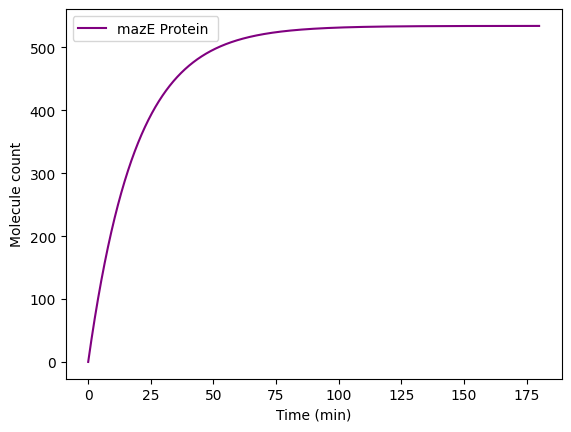

In [1]:
# Code for mazE ODEs

# import libraries
import numpy as np
import matplotlib.pyplot as plt

# Define parameters
k_syn_mazE = 28.32
gamma_maze = 0.053

time = 180
delta_t = 0.01
time_vec = np.arange(0, time, delta_t)
n_step = np.size(time_vec)

# Initialize variables
maze = np.zeros(n_step)

# Run for loop
for i in range(n_step - 1):
  dmaze_dt = k_syn_mazE - gamma_maze*maze[i]

  maze[i+1] = maze[i] + dmaze_dt*delta_t

# Plot results
print(f"Final mazE concentration: {np.round(maze[n_step-1],2)} copies")
plt.plot(time_vec, maze, label = 'mazE Protein ', color = 'purple')
plt.xlabel('Time (min)')
plt.ylabel('Molecule count')
plt.legend()
plt.show()

Maximum mazF concentration: 10015.13 nM


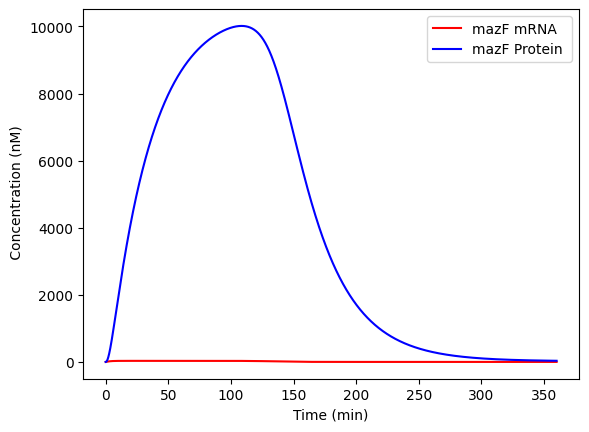

In [ ]:
# Code for mazF ODEs

import numpy as np
import matplotlib.pyplot as plt

# Define parameters
k_in = 100 # guessed
k_act = 1e-6 # must be significantly smaller than k_deact (should make sense biologically)
k_deact = 1
gamma_arb = 0.06
k_syn = 45.3
gamma_arac = 0.0415
h = 2
K_half = 40 # guessed
mu_mazf = 12
omega_mazf = 10
gamma_mazf = 0.376
chi_mazf = 0.03

time = 180*2
delta_t = 0.01
time_vec = np.arange(0, time, delta_t)
n_step = np.size(time_vec)

# Initialize variables
arabinose = np.zeros(n_step)
arabinose[0] = 1e8
AraC = np.zeros(n_step)
AraC[0] = 40
AraC_active = np.zeros(n_step)
mrna_mazf = np.zeros(n_step)
prot_mazf = np.zeros(n_step)

# Run for loop
for i in range(n_step - 1):
    # Calculate rates of change
    darb_dt = k_in - k_act*arabinose[i]*AraC[i] - gamma_arb*arabinose[i] + k_deact*AraC_active[i]
    dAraC_dt = k_syn - gamma_arac*AraC[i] - k_act*arabinose[i]*AraC[i] + k_deact*AraC_active[i]
    dAraC_active_dt = k_act*arabinose[i]*AraC[i] - k_deact*AraC_active[i] - gamma_arac*AraC_active[i]
    dmrna_mazf_dt = mu_mazf*(AraC_active[i]**h/(K_half**h + AraC_active[i]**h)) - gamma_mazf*mrna_mazf[i]
    dprot_mazf_dt = omega_mazf*mrna_mazf[i] - chi_mazf*prot_mazf[i]

    # Update variables, ensuring concentrations do not drop below zero
    arabinose[i+1] = arabinose[i] + darb_dt*delta_t
    AraC[i+1] = AraC[i] + dAraC_dt*delta_t
    AraC_active[i+1] =  AraC_active[i] + dAraC_active_dt*delta_t
    mrna_mazf[i+1] =  mrna_mazf[i] + dmrna_mazf_dt*delta_t
    prot_mazf[i+1] = prot_mazf[i] + dprot_mazf_dt*delta_t


# Plot results
print(f"Maximum mazF concentration: {np.round(np.max(prot_mazf),2)} nM")
plt.plot(time_vec, mrna_mazf, label = 'mazF mRNA ', color = 'red')
plt.plot(time_vec, prot_mazf, label = 'mazF Protein ', color = 'blue')
plt.xlabel('Time (min)')
plt.ylabel(' Concentration (nM)')
plt.legend()
plt.show()

Final mazE concentration: 1058.1 nM
Final mazF concentration: 2.91 nM


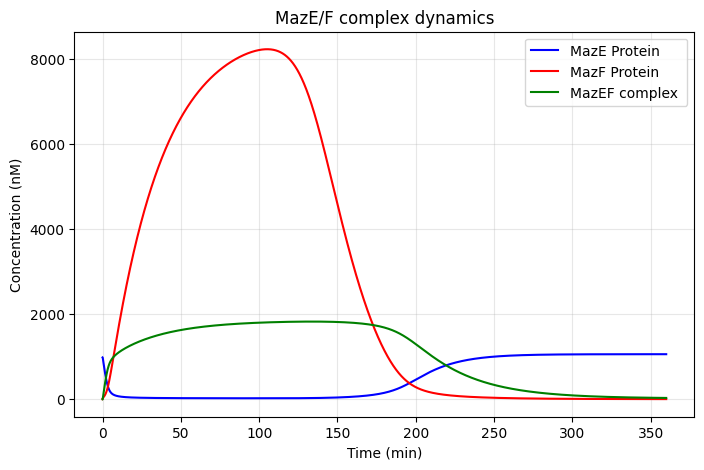

In [2]:
# Combine mazE and mazF together to account for mazEF binding
# Keep everything in nM so that units are consistent

# ------------ Newer plot -------------------

# import libraries
import numpy as np
import matplotlib.pyplot as plt

# Define parameters
k_syn_mazE = 28.32*2 # in nM/min
gamma_maze = 0.053
k_in = 100 # guessed
k_act = 1e-6 # must be significantly smaller than k_deact (should make sense biologically)
k_deact = 1
gamma_arb = 0.06
k_syn = 45.3
gamma_arac = 0.0415
h = 2
K_half = 40 # guessed
k_syn_mazF = 319.149
chi_mazf = 0.03
k_bind = 0.01
k_unbind = 1
chi_mazef = 0.03

time = 60*6
delta_t = 0.01
time_vec = np.arange(0, time, delta_t)
n_step = np.size(time_vec)

# Initialize variables
prot_maze = np.zeros(n_step)
prot_maze[0] = 982.69
arabinose = np.zeros(n_step)
arabinose[0] = 1e8
AraC = np.zeros(n_step)
AraC[0] = 400
AraC_active = np.zeros(n_step)
prot_mazf = np.zeros(n_step)
prot_mazef = np.zeros(n_step)


# Run for loop
for i in range(n_step - 1):
  dprot_mazef_dt = k_bind*prot_maze[i]*prot_mazf[i] - k_unbind*prot_mazef[i] - chi_mazef*prot_mazef[i]

  dprot_maze_dt = k_syn_mazE - gamma_maze*prot_maze[i] + k_unbind*prot_mazef[i] - k_bind*prot_maze[i]*prot_mazf[i]

  darb_dt = k_in - k_act*arabinose[i]*AraC[i] - gamma_arb*arabinose[i] + k_deact*AraC_active[i]
  dAraC_dt = k_syn - gamma_arac*AraC[i] - k_act*arabinose[i]*AraC[i] + k_deact*AraC_active[i]
  dAraC_active_dt = k_act*arabinose[i]*AraC[i] - k_deact*AraC_active[i] - gamma_arac*AraC_active[i]
  dprot_mazf_dt = k_syn_mazF*(AraC_active[i]**h/(K_half**h + AraC_active[i]**h)) - chi_mazf*prot_mazf[i] - k_bind*prot_maze[i]*prot_mazf[i] + k_unbind*prot_mazef[i]

  prot_maze[i+1] = prot_maze[i] + dprot_maze_dt*delta_t
# Update variables, ensuring concentrations do not drop below zero
  arabinose[i+1] =  arabinose[i] + darb_dt*delta_t
  AraC[i+1] = AraC[i] + dAraC_dt*delta_t
  AraC_active[i+1] =  AraC_active[i] + dAraC_active_dt*delta_t
  prot_mazf[i+1] = prot_mazf[i] + dprot_mazf_dt*delta_t
  prot_mazef[i+1] = prot_mazef[i] + dprot_mazef_dt*delta_t

# Plot mazE, mazF, and mazEF protein concentrations on the same plot, and compare results
figure = plt.figure(figsize=(8, 5))
print(f"Final mazE concentration: {np.round(prot_maze[n_step-1],2)} nM")
print(f"Final mazF concentration: {np.round(prot_mazf[n_step-1],2)} nM")
plt.plot(time_vec, prot_maze, label = 'MazE Protein ', color = 'blue')
plt.plot(time_vec, prot_mazf, label = 'MazF Protein ', color = 'red')
plt.plot(time_vec, prot_mazef, label = 'MazEF complex ', color = 'green')
plt.title('MazE/F complex dynamics')
plt.xlabel('Time (min)')
plt.ylabel('Concentration (nM)')
plt.grid(alpha = 0.3)
plt.legend()
plt.show()

Final mazE concentration: 970.06 nM
Final mazF concentration: 12.62 nM


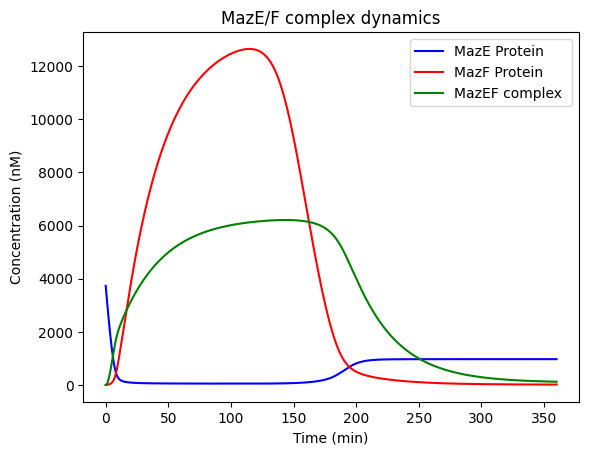

In [ ]:
# Combine mazE and mazF together to account for mazEF binding
# Keep everything in nM so that units are consistent

# ---------- Older plot --------------------------

# import libraries
import numpy as np
import matplotlib.pyplot as plt

# Define parameters
mu_maze = 4.05 # in nM/min
omega_maze = 10
gamma_maze = 0.203
chi_maze = 0.053
k_in = 100 # guessed
k_act = 1e-6 # must be significantly smaller than k_deact (should make sense biologically)
k_deact = 1
gamma_arb = 0.06
k_syn = 45.3
gamma_arac = 0.0415
h = 2
K_half = 25 # guessed
mu_mazf = 12
omega_mazf = 10
gamma_mazf = 0.203
chi_mazf = 0.03
k_bind = 0.01
k_unbind = 1
chi_mazef = 0.03

time = 60*6
delta_t = 0.01
time_vec = np.arange(0, time, delta_t)
n_step = np.size(time_vec)

# Initialize variables
mrna_maze = np.zeros(n_step)
mrna_maze[0] = 19.95
prot_maze = np.zeros(n_step)
prot_maze[0] = 3730.29
arabinose = np.zeros(n_step)
arabinose[0] = 1e8
AraC = np.zeros(n_step)
AraC[0] = 40
AraC_active = np.zeros(n_step)
mrna_mazf = np.zeros(n_step)
prot_mazf = np.zeros(n_step)
prot_mazef = np.zeros(n_step)


# Run for loop
for i in range(n_step - 1):
  dprot_mazef_dt = k_bind*prot_maze[i]*prot_mazf[i] - k_unbind*prot_mazef[i] - chi_mazef*prot_mazef[i]
  dmrna_maze_dt = mu_maze - gamma_maze*mrna_maze[i]
  dprot_maze_dt = omega_maze*mrna_maze[i] - gamma_maze*prot_maze[i] + k_unbind*prot_mazef[i] - k_bind*prot_maze[i]*prot_mazf[i]

  darb_dt = k_in - k_act*arabinose[i]*AraC[i] - gamma_arb*arabinose[i] + k_deact*AraC_active[i]
  dAraC_dt = k_syn - gamma_arac*AraC[i] - k_act*arabinose[i]*AraC[i] + k_deact*AraC_active[i]
  dAraC_active_dt = k_act*arabinose[i]*AraC[i] - k_deact*AraC_active[i] - gamma_arac*AraC_active[i]
  dmrna_mazf_dt = mu_mazf*(AraC_active[i]**h/(K_half**h + AraC_active[i]**h)) - gamma_mazf*mrna_mazf[i]
  dprot_mazf_dt = omega_mazf*mrna_mazf[i] - chi_mazf*prot_mazf[i] - k_bind*prot_maze[i]*prot_mazf[i] + k_unbind*prot_mazef[i]

  prot_maze[i+1] = prot_maze[i] + dprot_maze_dt*delta_t
# Update variables, ensuring concentrations do not drop below zero
  arabinose[i+1] =  arabinose[i] + darb_dt*delta_t
  AraC[i+1] = AraC[i] + dAraC_dt*delta_t
  AraC_active[i+1] =  AraC_active[i] + dAraC_active_dt*delta_t
  mrna_maze[i+1] =  mrna_maze[i] + dmrna_maze_dt*delta_t
  mrna_mazf[i+1] =  mrna_mazf[i] + dmrna_mazf_dt*delta_t
  prot_mazf[i+1] = prot_mazf[i] + dprot_mazf_dt*delta_t
  prot_mazef[i+1] = prot_mazef[i] + dprot_mazef_dt*delta_t

# Plot mazE, mazF, and mazEF protein concentrations on the same plot, and compare results
print(f"Final mazE concentration: {np.round(prot_maze[n_step-1],2)} nM")
print(f"Final mazF concentration: {np.round(prot_mazf[n_step-1],2)} nM")
plt.plot(time_vec, prot_maze, label = 'MazE Protein ', color = 'blue')
plt.plot(time_vec, prot_mazf, label = 'MazF Protein ', color = 'red')
plt.plot(time_vec, prot_mazef, label = 'MazEF complex ', color = 'green')
plt.title('MazE/F complex dynamics')
plt.xlabel('Time (min)')
plt.ylabel('Concentration (nM)')
plt.legend()
plt.show()